<a href="https://colab.research.google.com/github/aditiprasannna/DLG-lab/blob/main/lab6_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow Version: 2.21.0

Dataset Shape: (1000, 30)
Sample Melody: ['B3', 'C4', 'B3', 'C4', 'D4', 'D4', 'B3', 'C4', 'B3', 'A3', 'B3', 'G3', 'A3', 'C4', 'A3', 'C4', 'D4', 'E4', 'C4', 'A3', 'B3', 'B3', 'G3', 'B3', 'A3', 'F3', 'G3', 'G3', 'B3', 'C4']

Input Shape: (1000, 29, 50)
Target Shape: (1000, 29, 50)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 365ms/step - accuracy: 0.2069 - loss: 3.5475 - val_accuracy: 0.1934 - val_loss: 2.7732
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 438ms/step - accuracy: 0.2200 - loss: 2.3901 - val_accuracy: 0.2374 - val_loss: 2.1286
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 384ms/step - accuracy: 0.2607 - loss: 2.0003 - val_accuracy: 0.2809 - val_loss: 1.9077
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 377ms/step - accuracy: 0.3113 - loss: 1.8012 - val_accuracy: 0.3378 - val_loss: 1.7178
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 295ms/step - accuracy: 0.3564 - loss: 1.6318 - val_accuracy: 0.3771 - val_loss: 1.5669
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 287ms/step - accuracy: 0.3967 - loss: 1.4874 - val_accuracy: 0.4184 - val_loss: 1.4323
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 449ms/step - accuracy: 0.4345 - loss: 1.3642 - val_accuracy: 0.4547 - val_loss: 1.3159
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 296ms/step - accuracy: 0.4772 - loss: 1.2560 - val_accuracy: 

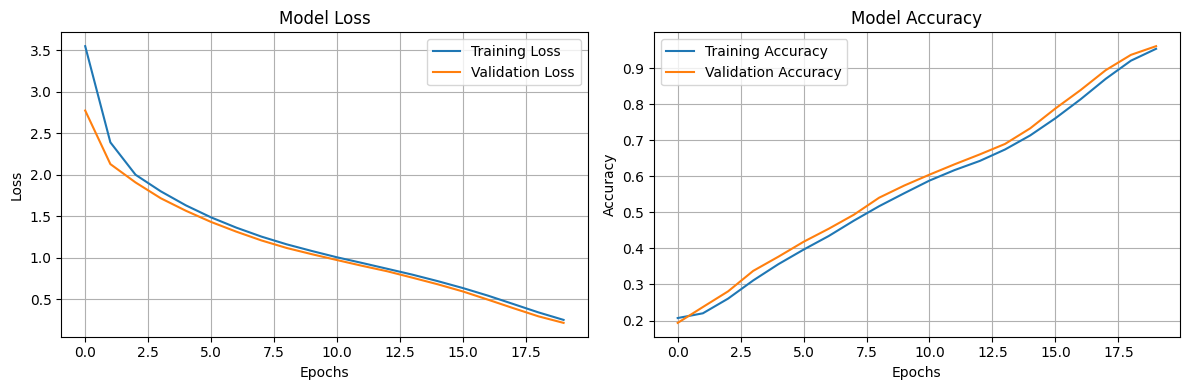


       GENERATED MUSIC

C4  B3  C4  D4  A3  B3  A#5  C4  E4  D4  
E4  F4  E4  E4  C4  A3  B3  D4  F4  F4  
G4  A4  A4  A4  A4  A4  G4  A4  E4  E4  
E4  C5  C5  C5  D5  G5  G5  G5  A5  A5  
C6  E6  F6  F6  A6  G6  F6  F6  G6  A6  


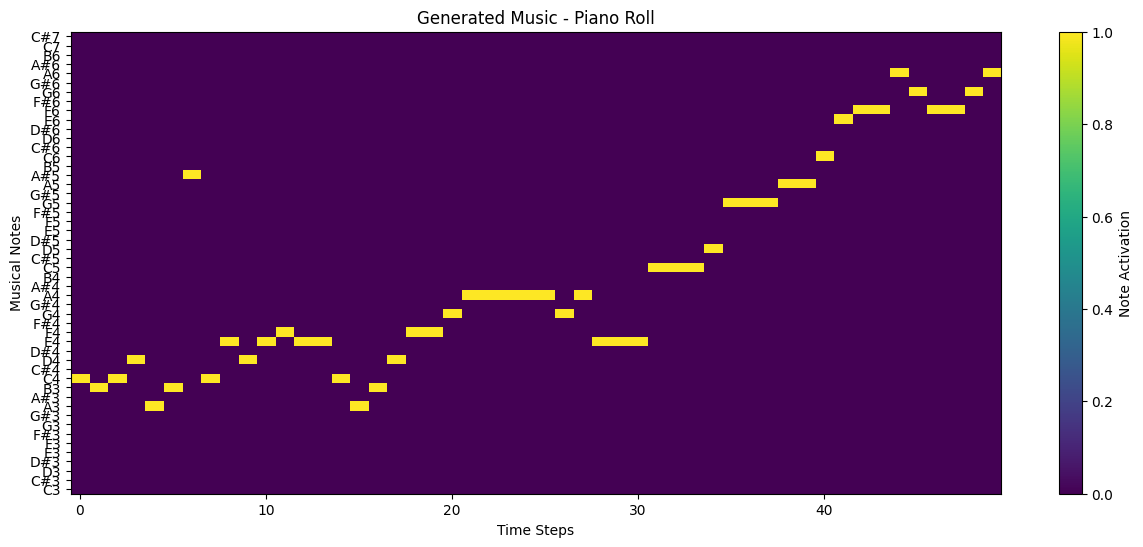


Playing Generated Music...



WAV file saved: Generated_Music.wav

For MIDI export, install pretty_midi using:
!pip install pretty_midi

       MUSIC GENERATION COMPLETE

Generated Notes:
C4 -> B3 -> C4 -> D4 -> A3 -> B3 -> A#5 -> C4 -> E4 -> D4 -> E4 -> F4 -> E4 -> E4 -> C4 -> A3 -> B3 -> D4 -> F4 -> F4 -> G4 -> A4 -> A4 -> A4 -> A4 -> A4 -> G4 -> A4 -> E4 -> E4 -> E4 -> C5 -> C5 -> C5 -> D5 -> G5 -> G5 -> G5 -> A5 -> A5 -> C6 -> E6 -> F6 -> F6 -> A6 -> G6 -> F6 -> F6 -> G6 -> A6

Files created:
1. Generated_Music.wav
2. Generated_Music.mid (if pretty_midi is installed)

You can listen to the generated melody using the audio player above.


In [3]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from IPython.display import Audio, display
from scipy.io.wavfile import write

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)

# ============================================================
# 1. PARAMETERS AND MUSICAL NOTES
# ============================================================

num_notes = 50
sequence_length = 30
num_sequences = 1000

# MIDI pitches from 48 to 97
midi_notes = np.arange(48, 98)

def midi_to_note(midi):
    names = ['C', 'C#', 'D', 'D#', 'E', 'F',
             'F#', 'G', 'G#', 'A', 'A#', 'B']
    return names[midi % 12] + str((midi // 12) - 1)

note_names = [midi_to_note(n) for n in midi_notes]

# ============================================================
# 2. CREATE MUSICAL TRAINING DATA
# ============================================================

# C major scale across multiple octaves
scale_notes = [
    48, 50, 52, 53, 55, 57, 59,
    60, 62, 64, 65, 67, 69, 71,
    72, 74, 76, 77, 79, 81, 83,
    84, 86, 88, 89, 91, 93, 95
]

data = []

for _ in range(num_sequences):

    melody = []
    current_note = np.random.choice(scale_notes)

    for i in range(sequence_length):

        melody.append(current_note)

        current_index = scale_notes.index(current_note)

        movement = np.random.choice(
            [-2, -1, 0, 1, 2],
            p=[0.10, 0.25, 0.10, 0.40, 0.15]
        )

        new_index = np.clip(
            current_index + movement,
            0,
            len(scale_notes) - 1
        )

        current_note = scale_notes[new_index]

    data.append(melody)

data = np.array(data) - 48

print("\nDataset Shape:", data.shape)
print("Sample Melody:", [note_names[n] for n in data[0]])

# ============================================================
# 3. PREPARE INPUT AND TARGET DATA
# ============================================================

x_train = data[:, :-1]
y_train = data[:, 1:]

x_train = to_categorical(x_train, num_classes=num_notes)
y_train = to_categorical(y_train, num_classes=num_notes)

print("\nInput Shape:", x_train.shape)
print("Target Shape:", y_train.shape)

# ============================================================
# 4. BUILD BIDIRECTIONAL LSTM MODEL
# ============================================================

model = models.Sequential()

model.add(layers.Input(shape=(sequence_length - 1, num_notes)))

model.add(
    layers.Bidirectional(
        layers.LSTM(128, return_sequences=True)
    )
)

model.add(
    layers.Bidirectional(
        layers.LSTM(128, return_sequences=True)
    )
)

model.add(
    layers.TimeDistributed(
        layers.Dense(num_notes, activation='softmax')
    )
)

model.summary()

# ============================================================
# 5. COMPILE AND TRAIN MODEL
# ============================================================

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

# ============================================================
# 6. PLOT TRAINING ACCURACY AND LOSS
# ============================================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# ============================================================
# 7. MUSIC GENERATION FUNCTION
# ============================================================

def generate_music(model, start_sequence,
                   num_generated_notes=50, temperature=0.8):

    generated = []
    current_sequence = start_sequence.copy()

    for _ in range(num_generated_notes):

        prediction = model.predict(
            current_sequence, verbose=0
        )

        probabilities = prediction[0, -1, :]

        # Temperature-based sampling
        probabilities = np.asarray(probabilities, dtype='float64')
        probabilities = np.log(probabilities + 1e-8) / temperature
        probabilities = np.exp(
            probabilities - np.max(probabilities)
        )
        probabilities /= np.sum(probabilities)

        next_note = np.random.choice(
            num_notes, p=probabilities
        )

        generated.append(next_note)

        new_note = to_categorical(
            [next_note], num_classes=num_notes
        ).reshape(1, 1, num_notes)

        current_sequence = np.concatenate(
            [current_sequence[:, 1:, :], new_note],
            axis=1
        )

    return generated

# ============================================================
# 8. GENERATE AND DISPLAY MUSICAL NOTES
# ============================================================

start = data[0:1, :-1]

start = to_categorical(
    start, num_classes=num_notes
)

generated_music = generate_music(
    model,
    start,
    num_generated_notes=50,
    temperature=0.8
)

generated_note_names = [
    note_names[n] for n in generated_music
]

print("\n================================")
print("       GENERATED MUSIC")
print("================================\n")

for i, note in enumerate(generated_note_names, 1):
    print(note, end="  ")

    if i % 10 == 0:
        print()

# ============================================================
# 9. PIANO ROLL VISUALIZATION
# ============================================================

piano_roll = np.zeros((num_notes, len(generated_music)))

for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1

plt.figure(figsize=(15, 6))

plt.imshow(
    piano_roll,
    aspect='auto',
    cmap='viridis',
    origin='lower',
    interpolation='nearest'
)

plt.yticks(range(num_notes), note_names)
plt.colorbar(label='Note Activation')

plt.title('Generated Music - Piano Roll')
plt.xlabel('Time Steps')
plt.ylabel('Musical Notes')

plt.show()

# ============================================================
# 10. CONVERT MUSICAL NOTES INTO AUDIO
# ============================================================

def generate_audio(notes, duration=0.4, sample_rate=44100):

    audio = []

    for note in notes:

        midi_pitch = 48 + note

        frequency = 440 * (2 ** ((midi_pitch - 69) / 12))

        t = np.linspace(
            0,
            duration,
            int(sample_rate * duration),
            endpoint=False
        )

        # Piano-like sound with harmonics
        sound = (
            np.sin(2 * np.pi * frequency * t) +
            0.35 * np.sin(2 * np.pi * frequency * 2 * t) +
            0.15 * np.sin(2 * np.pi * frequency * 3 * t)
        )

        # Fading envelope
        envelope = np.exp(-4 * t / duration)

        sound = sound * envelope

        audio.append(sound)

    audio = np.concatenate(audio)

    audio = audio / (np.max(np.abs(audio)) + 1e-8)

    return audio

audio_output = generate_audio(generated_music)

print("\nPlaying Generated Music...")

display(Audio(audio_output, rate=44100))

# ============================================================
# 11. SAVE AUDIO AS WAV FILE
# ============================================================

audio_int16 = np.int16(audio_output * 32767)

write(
    "Generated_Music.wav",
    44100,
    audio_int16
)

print("\nWAV file saved: Generated_Music.wav")

# ============================================================
# 12. SAVE MUSIC AS MIDI FILE
# ============================================================

try:
    import pretty_midi

    midi = pretty_midi.PrettyMIDI()

    piano = pretty_midi.Instrument(program=0)

    for i, note in enumerate(generated_music):

        midi_note = pretty_midi.Note(
            velocity=100,
            pitch=48 + note,
            start=i * 0.4,
            end=(i + 1) * 0.4
        )

        piano.notes.append(midi_note)

    midi.instruments.append(piano)

    midi.write("Generated_Music.mid")

    print("MIDI file saved: Generated_Music.mid")

except ImportError:
    print("\nFor MIDI export, install pretty_midi using:")
    print("!pip install pretty_midi")

# ============================================================
# 13. FINAL OUTPUT
# ============================================================

print("\n================================")
print("       MUSIC GENERATION COMPLETE")
print("================================")

print("\nGenerated Notes:")
print(" -> ".join(generated_note_names))

print("\nFiles created:")
print("1. Generated_Music.wav")
print("2. Generated_Music.mid (if pretty_midi is installed)")

print("\nYou can listen to the generated melody using the audio player above.")
